In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Diretório raiz do projeto
PROJECT_ROOT = Path.cwd().parent

# Caminho do arquivo
FILE_PATH = PROJECT_ROOT / "data" / "bronze" / "anac" / "vra" / "2022" / "VRA_20221.csv"

# Carregar os dados
df_raw = pd.read_csv(
    FILE_PATH,
    encoding="utf-8-sig",
    sep=";",
    skiprows=1,
    quotechar='"',
    dtype=str,
    keep_default_na=False
)

print(f"Registros: {df_raw.shape[0]:,}")
print(f"Colunas: {df_raw.shape[1]}")

Registros: 73,343
Colunas: 12


In [2]:
df = df_raw.copy()

# Remover espaços extras
df = df.apply(lambda col: col.str.strip())

# Transformar strings vazias em valores ausentes
df = df.replace("", pd.NA)

DATE_COLUMNS = [
    "Partida Prevista",
    "Partida Real",
    "Chegada Prevista",
    "Chegada Real"
]

# Converter as datas
parsed_dates = pd.DataFrame({
    col: pd.to_datetime(
        df[col],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )
    for col in DATE_COLUMNS
})

parsed_dates.head()

,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real
0,2022-01-03 22:50:00,2022-01-03 22:39:00,2022-01-04 00:45:00,2022-01-04 00:29:00
1,2022-01-04 22:50:00,2022-01-04 22:37:00,2022-01-05 00:45:00,2022-01-05 00:25:00
2,2022-01-05 22:50:00,2022-01-05 23:03:00,2022-01-06 00:45:00,2022-01-06 00:47:00
3,2022-01-06 22:50:00,2022-01-06 22:37:00,2022-01-07 00:45:00,2022-01-07 00:19:00
4,2022-01-07 22:50:00,2022-01-07 22:38:00,2022-01-08 00:45:00,2022-01-08 00:25:00


In [3]:
print("Valores ausentes ou inválidos após conversão:\n")

print(parsed_dates.isna().sum())

print("\nPercentual por coluna:\n")

print(
    (parsed_dates.isna().mean() * 100).round(2)
)

Valores ausentes ou inválidos após conversão:

Partida Prevista    2651
Partida Real        3206
Chegada Prevista    2651
Chegada Real        3206
dtype: int64

Percentual por coluna:

Partida Prevista    3.61
Partida Real        4.37
Chegada Prevista    3.61
Chegada Real        4.37
dtype: float64


In [8]:
realizados = df["Situação Voo"].eq("REALIZADO")

invalid_dates = realizados & parsed_dates.isna().any(axis=1)

print("Voos realizados:", realizados.sum())
print("Voos com alguma data inválida:", invalid_dates.sum())

df.loc[invalid_dates, DATE_COLUMNS + ["ICAO Empresa Aérea", "Número Voo"]].head(20)

Voos realizados: 70137
Voos com alguma data inválida: 2651


,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,ICAO Empresa Aérea,Número Voo
34,null,2022-01-24 06:46:00,null,2022-01-24 07:14:00,LPE,Z2383
35,null,2022-01-02 09:30:00,null,2022-01-02 10:00:00,ABJ,1402
36,null,2022-01-03 09:30:00,null,2022-01-03 10:00:00,ABJ,1402
37,null,2022-01-05 09:30:00,null,2022-01-05 10:00:00,ABJ,1402
38,null,2022-01-02 10:15:00,null,2022-01-02 10:45:00,ABJ,1403
39,null,2022-01-03 10:15:00,null,2022-01-03 10:45:00,ABJ,1403
40,null,2022-01-05 10:15:00,null,2022-01-05 10:45:00,ABJ,1403
41,null,2022-01-01 11:15:00,null,2022-01-01 11:45:00,ABJ,1404
42,null,2022-01-02 11:15:00,null,2022-01-02 11:45:00,ABJ,1404
43,null,2022-01-03 11:15:00,null,2022-01-03 11:45:00,ABJ,1404


In [10]:
df_analysis = df.copy()

for col in DATE_COLUMNS:
    df_analysis[col] = parsed_dates[col]

df_analysis["Atraso Partida (min)"] = (
    df_analysis["Partida Real"] -
    df_analysis["Partida Prevista"]
).dt.total_seconds() / 60

df_analysis["Atraso Chegada (min)"] = (
    df_analysis["Chegada Real"] -
    df_analysis["Chegada Prevista"]
).dt.total_seconds() / 60

# Considerar somente voos realizados
realizados = df_analysis["Situação Voo"].eq("REALIZADO")

delay_columns = [
    "Atraso Partida (min)",
    "Atraso Chegada (min)"
]

df_analysis.loc[~realizados, delay_columns] = np.nan

In [11]:
df_analysis.sort_values(
    "Atraso Chegada (min)",
    ascending=False
)[
    [
        "ICAO Empresa Aérea",
        "Número Voo",
        "ICAO Aeródromo Origem",
        "ICAO Aeródromo Destino",
        "Chegada Prevista",
        "Chegada Real",
        "Atraso Chegada (min)"
    ]
].head(10)

,ICAO Empresa Aérea,Número Voo,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Chegada Prevista,Chegada Real,Atraso Chegada (min)
57723,GTI,8228,KMIA,SBGR,2022-01-15 06:25:00,2022-01-18 13:16:00,4731.0
57727,GTI,8228,SBGR,SCEL,2022-01-15 13:10:00,2022-01-18 18:56:00,4666.0
57598,GTI,0036,SBEG,SEQM,2022-01-18 17:05:00,2022-01-21 01:10:00,3365.0
60181,MPH,7341,EHAM,SBKP,2022-01-07 03:50:00,2022-01-09 07:02:00,3072.0
57698,GTI,8050,KMIA,SBGR,2022-01-19 06:40:00,2022-01-21 07:53:00,2953.0
57702,GTI,8050,SBGR,SCEL,2022-01-19 14:00:00,2022-01-21 13:44:00,2864.0
57648,GTI,0058,SBKP,SEQM,2022-01-08 21:50:00,2022-01-10 16:47:00,2577.0
57610,GTI,0039,KMIA,SBEG,2022-01-09 12:20:00,2022-01-11 07:05:00,2565.0
57615,GTI,0040,SBEG,SEQM,2022-01-09 17:20:00,2022-01-11 11:40:00,2540.0
2836,LTG,8451,KMIA,SBEG,2022-01-08 19:20:00,2022-01-10 10:18:00,2338.0


In [12]:
df_analysis.sort_values(
    "Atraso Chegada (min)",
    ascending=True
)[
    [
        "ICAO Empresa Aérea",
        "Número Voo",
        "ICAO Aeródromo Origem",
        "ICAO Aeródromo Destino",
        "Chegada Prevista",
        "Chegada Real",
        "Atraso Chegada (min)"
    ]
].head(10)

,ICAO Empresa Aérea,Número Voo,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Chegada Prevista,Chegada Real,Atraso Chegada (min)
57892,THY,6409,KMIA,SBGR,2022-01-13 22:55:00,2022-01-12 13:03:00,-2032.0
26244,UAL,0860,SBGR,KIAD,2022-01-21 11:00:00,2022-01-20 10:09:00,-1491.0
30192,AZU,2004,SBBE,SBFZ,2022-01-02 14:25:00,2022-01-01 13:45:00,-1480.0
4355,CMP,0765,MPTO,SBCF,2022-01-23 00:25:00,2022-01-21 23:55:00,-1470.0
4363,CMP,0765,MPTO,SBCF,2022-02-01 00:25:00,2022-01-30 23:57:00,-1468.0
4356,CMP,0765,MPTO,SBCF,2022-01-24 00:25:00,2022-01-22 23:58:00,-1467.0
4352,CMP,0765,MPTO,SBCF,2022-01-19 00:25:00,2022-01-17 23:59:00,-1466.0
4346,CMP,0765,MPTO,SBCF,2022-01-12 00:25:00,2022-01-11 00:02:00,-1463.0
816,ETH,0507,SBGR,HAAB,2022-01-17 13:45:00,2022-01-16 13:26:00,-1459.0
808,ETH,0507,SAEZ,SBGR,2022-01-28 00:05:00,2022-01-26 23:46:00,-1459.0


In [13]:
for col in DATE_COLUMNS:
    print(f"\n{col}")
    print(
        pd.crosstab(
            df["Situação Voo"],
            parsed_dates[col].isna(),
            margins=True
        )
    )


Partida Prevista
Partida Prevista  False  True    All
Situação Voo                        
CANCELADO          3206     0   3206
REALIZADO         67486  2651  70137
All               70692  2651  73343

Partida Real
Partida Real  False  True    All
Situação Voo                    
CANCELADO         0  3206   3206
REALIZADO     70137     0  70137
All           70137  3206  73343

Chegada Prevista
Chegada Prevista  False  True    All
Situação Voo                        
CANCELADO          3206     0   3206
REALIZADO         67486  2651  70137
All               70692  2651  73343

Chegada Real
Chegada Real  False  True    All
Situação Voo                    
CANCELADO         0  3206   3206
REALIZADO     70137     0  70137
All           70137  3206  73343


In [14]:
df.loc[invalid_dates].head(10).to_string()

'   ICAO Empresa Aérea Número Voo Código Autorização (DI) Código Tipo Linha ICAO Aeródromo Origem ICAO Aeródromo Destino Partida Prevista         Partida Real Chegada Prevista         Chegada Real Situação Voo Código Justificativa\n34                LPE      Z2383                       3                 I                  SBGR                   SBGR             null  2022-01-24 06:46:00             null  2022-01-24 07:14:00    REALIZADO                  N/A\n35                ABJ       1402                       2                 N                  SBSV                   SNCL             null  2022-01-02 09:30:00             null  2022-01-02 10:00:00    REALIZADO                  N/A\n36                ABJ       1402                       2                 N                  SBSV                   SNCL             null  2022-01-03 09:30:00             null  2022-01-03 10:00:00    REALIZADO                  N/A\n37                ABJ       1402                       2                 N 

In [15]:
extreme_delays = (
    df_analysis.loc[realizados]
    .sort_values(
        "Atraso Chegada (min)",
        ascending=False
    )
    .head(10)
)

display(extreme_delays)

,ICAO Empresa Aérea,Número Voo,Código Autorização (DI),Código Tipo Linha,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Situação Voo,Código Justificativa,Atraso Partida (min),Atraso Chegada (min)
57723,GTI,8228,0,G,KMIA,SBGR,2022-01-14 22:15:00,2022-01-18 05:14:00,2022-01-15 06:25:00,2022-01-18 13:16:00,REALIZADO,N/A,4739.0,4731.0
57727,GTI,8228,0,G,SBGR,SCEL,2022-01-15 08:40:00,2022-01-18 15:01:00,2022-01-15 13:10:00,2022-01-18 18:56:00,REALIZADO,N/A,4701.0,4666.0
57598,GTI,0036,0,G,SBEG,SEQM,2022-01-18 14:05:00,2022-01-20 21:48:00,2022-01-18 17:05:00,2022-01-21 01:10:00,REALIZADO,N/A,3343.0,3365.0
60181,MPH,7341,0,G,EHAM,SBKP,2022-01-06 16:05:00,2022-01-08 19:26:00,2022-01-07 03:50:00,2022-01-09 07:02:00,REALIZADO,N/A,3081.0,3072.0
57698,GTI,8050,0,G,KMIA,SBGR,2022-01-18 22:30:00,2022-01-20 22:56:00,2022-01-19 06:40:00,2022-01-21 07:53:00,REALIZADO,N/A,2906.0,2953.0
57702,GTI,8050,0,G,SBGR,SCEL,2022-01-19 09:30:00,2022-01-21 10:13:00,2022-01-19 14:00:00,2022-01-21 13:44:00,REALIZADO,N/A,2923.0,2864.0
57648,GTI,0058,0,G,SBKP,SEQM,2022-01-08 16:10:00,2022-01-10 11:14:00,2022-01-08 21:50:00,2022-01-10 16:47:00,REALIZADO,N/A,2584.0,2577.0
57610,GTI,0039,2,I,KMIA,SBEG,2022-01-09 07:20:00,2022-01-11 01:39:00,2022-01-09 12:20:00,2022-01-11 07:05:00,REALIZADO,N/A,2539.0,2565.0
57615,GTI,0040,0,G,SBEG,SEQM,2022-01-09 14:20:00,2022-01-11 08:38:00,2022-01-09 17:20:00,2022-01-11 11:40:00,REALIZADO,N/A,2538.0,2540.0
2836,LTG,8451,0,G,KMIA,SBEG,2022-01-08 14:10:00,2022-01-10 05:07:00,2022-01-08 19:20:00,2022-01-10 10:18:00,REALIZADO,N/A,2337.0,2338.0


In [16]:
# Selecionar voos realizados sem horário previsto
unplanned_flights = df.loc[
    realizados & parsed_dates["Partida Prevista"].isna()
].copy()

print("Voos realizados sem partida prevista:")
print(len(unplanned_flights))

print("\nDistribuição por Código DI:")
display(
    unplanned_flights["Código Autorização (DI)"]
    .value_counts(dropna=False)
)

print("\nDistribuição por Tipo de Linha:")
display(
    unplanned_flights["Código Tipo Linha"]
    .value_counts(dropna=False)
)

Voos realizados sem partida prevista:
2651

Distribuição por Código DI:


Código Autorização (DI)
2    1282
6     421
4     345
3     309
1      99
D      76
9      48
7      38
E      33
Name: count, dtype: int64


Distribuição por Tipo de Linha:


Código Tipo Linha
N    1895
I     367
G     229
C     160
Name: count, dtype: int64

In [17]:
pd.crosstab(
    unplanned_flights["Código Autorização (DI)"],
    unplanned_flights["Código Tipo Linha"],
    margins=True
)

Código Tipo Linha,C,G,I,N,All
Código Autorização (DI),,,,,
1,2,4,74,19,99
2,91,18,209,964,1282
3,6,0,8,295,309
4,5,94,21,225,345
6,20,1,37,363,421
7,21,2,9,6,38
9,0,34,8,6,48
D,0,76,0,0,76
E,15,0,1,17,33


In [18]:
# Considerar voos realizados com horários previstos e reais
valid_delays = (
    realizados
    & parsed_dates["Partida Prevista"].notna()
    & parsed_dates["Partida Real"].notna()
    & parsed_dates["Chegada Prevista"].notna()
    & parsed_dates["Chegada Real"].notna()
)

delay_summary = df_analysis.loc[valid_delays].groupby(
    "Código Tipo Linha"
)[
    ["Atraso Partida (min)", "Atraso Chegada (min)"]
].agg(["count", "median", "mean", "max"])

display(delay_summary)

Atraso Partida (min)                             \
                                 count median        mean     max   
Código Tipo Linha                                                   
C                                 1308    0.0    7.809633  1566.0   
G                                 1193   19.0  148.638726  4739.0   
I                                 5861    4.0    5.942843  2539.0   
N                                59124   -1.0    5.057675  1426.0   

                  Atraso Chegada (min)                             
                                 count median        mean     max  
Código Tipo Linha                                                  
C                                 1308    2.0    9.457187  1573.0  
G                                 1193   20.0  146.461861  4731.0  
I                                 5861   -5.0   -6.435250  2565.0  
N                                59124   -3.0    2.163791  1424.0

In [19]:
extreme = df_analysis.loc[
    valid_delays
    & (df_analysis["Atraso Chegada (min)"] > 1440)
]

print("Voos com atraso superior a 24 horas:", len(extreme))

display(
    extreme.groupby(
        ["ICAO Empresa Aérea", "Código Tipo Linha"]
    ).size().sort_values(ascending=False).head(15)
)

Voos com atraso superior a 24 horas: 42


ICAO Empresa Aérea  Código Tipo Linha
GTI                 G                    22
AZU                 C                    10
ACA                 I                     2
GTI                 I                     2
TPA                 G                     2
CMP                 I                     1
LCO                 G                     1
LTG                 G                     1
MPH                 G                     1
dtype: int64

In [20]:
# Duração prevista e real dos voos
df_analysis["Duração Prevista (min)"] = (
    df_analysis["Chegada Prevista"] -
    df_analysis["Partida Prevista"]
).dt.total_seconds() / 60

df_analysis["Duração Real (min)"] = (
    df_analysis["Chegada Real"] -
    df_analysis["Partida Real"]
).dt.total_seconds() / 60

# Diferença entre duração real e prevista
df_analysis["Diferença de Duração (min)"] = (
    df_analysis["Duração Real (min)"] -
    df_analysis["Duração Prevista (min)"]
)

In [21]:
extreme_delays = df_analysis.loc[
    df_analysis["Atraso Chegada (min)"] > 1440
].copy()

columns = [
    "ICAO Empresa Aérea",
    "Número Voo",
    "ICAO Aeródromo Origem",
    "ICAO Aeródromo Destino",
    "Partida Prevista",
    "Partida Real",
    "Chegada Prevista",
    "Chegada Real",
    "Atraso Partida (min)",
    "Atraso Chegada (min)",
    "Duração Prevista (min)",
    "Duração Real (min)",
    "Diferença de Duração (min)"
]

display(
    extreme_delays[columns]
    .sort_values("Atraso Chegada (min)", ascending=False)
)

,ICAO Empresa Aérea,Número Voo,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Atraso Partida (min),Atraso Chegada (min),Duração Prevista (min),Duração Real (min),Diferença de Duração (min)
57723,GTI,8228,KMIA,SBGR,2022-01-14 22:15:00,2022-01-18 05:14:00,2022-01-15 06:25:00,2022-01-18 13:16:00,4739.0,4731.0,490.0,482.0,-8.0
57727,GTI,8228,SBGR,SCEL,2022-01-15 08:40:00,2022-01-18 15:01:00,2022-01-15 13:10:00,2022-01-18 18:56:00,4701.0,4666.0,270.0,235.0,-35.0
57598,GTI,0036,SBEG,SEQM,2022-01-18 14:05:00,2022-01-20 21:48:00,2022-01-18 17:05:00,2022-01-21 01:10:00,3343.0,3365.0,180.0,202.0,22.0
60181,MPH,7341,EHAM,SBKP,2022-01-06 16:05:00,2022-01-08 19:26:00,2022-01-07 03:50:00,2022-01-09 07:02:00,3081.0,3072.0,705.0,696.0,-9.0
57698,GTI,8050,KMIA,SBGR,2022-01-18 22:30:00,2022-01-20 22:56:00,2022-01-19 06:40:00,2022-01-21 07:53:00,2906.0,2953.0,490.0,537.0,47.0
57702,GTI,8050,SBGR,SCEL,2022-01-19 09:30:00,2022-01-21 10:13:00,2022-01-19 14:00:00,2022-01-21 13:44:00,2923.0,2864.0,270.0,211.0,-59.0
57648,GTI,0058,SBKP,SEQM,2022-01-08 16:10:00,2022-01-10 11:14:00,2022-01-08 21:50:00,2022-01-10 16:47:00,2584.0,2577.0,340.0,333.0,-7.0
57610,GTI,0039,KMIA,SBEG,2022-01-09 07:20:00,2022-01-11 01:39:00,2022-01-09 12:20:00,2022-01-11 07:05:00,2539.0,2565.0,300.0,326.0,26.0
57615,GTI,0040,SBEG,SEQM,2022-01-09 14:20:00,2022-01-11 08:38:00,2022-01-09 17:20:00,2022-01-11 11:40:00,2538.0,2540.0,180.0,182.0,2.0
2836,LTG,8451,KMIA,SBEG,2022-01-08 14:10:00,2022-01-10 05:07:00,2022-01-08 19:20:00,2022-01-10 10:18:00,2337.0,2338.0,310.0,311.0,1.0


In [22]:
extreme_delays["Diferença entre atrasos (min)"] = (
    extreme_delays["Atraso Chegada (min)"]
    - extreme_delays["Atraso Partida (min)"]
)

display(
    extreme_delays[
        [
            "ICAO Empresa Aérea",
            "Número Voo",
            "ICAO Aeródromo Origem",
            "ICAO Aeródromo Destino",
            "Atraso Partida (min)",
            "Atraso Chegada (min)",
            "Diferença entre atrasos (min)",
            "Diferença de Duração (min)"
        ]
    ]
)

,ICAO Empresa Aérea,Número Voo,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Atraso Partida (min),Atraso Chegada (min),Diferença entre atrasos (min),Diferença de Duração (min)
2836,LTG,8451,KMIA,SBEG,2337.0,2338.0,1.0,1.0
3432,TPA,4051,KMIA,SBKP,1530.0,1536.0,6.0,6.0
3436,TPA,4052,SBKP,SKBO,1530.0,1488.0,-42.0,-42.0
4593,CMP,0872,SBGL,MPTO,1448.0,1442.0,-6.0,-6.0
29325,AZU,2035,SBEG,SBKP,1493.0,1477.0,-16.0,-16.0
29327,AZU,2035,SBEG,SBKP,1456.0,1445.0,-11.0,-11.0
29331,AZU,2035,SBEG,SBKP,1494.0,1475.0,-19.0,-19.0
29332,AZU,2035,SBEG,SBKP,1498.0,1496.0,-2.0,-2.0
29333,AZU,2035,SBEG,SBKP,1460.0,1464.0,4.0,4.0
29334,AZU,2035,SBEG,SBKP,1468.0,1462.0,-6.0,-6.0


In [23]:
extreme_delays["Dias de deslocamento"] = (
    extreme_delays["Atraso Partida (min)"] / 1440
)

display(
    extreme_delays[
        [
            "ICAO Empresa Aérea",
            "Número Voo",
            "Atraso Partida (min)",
            "Dias de deslocamento"
        ]
    ].sort_values("Atraso Partida (min)", ascending=False)
)

,ICAO Empresa Aérea,Número Voo,Atraso Partida (min),Dias de deslocamento
57723,GTI,8228,4739.0,3.290972
57727,GTI,8228,4701.0,3.264583
57598,GTI,0036,3343.0,2.321528
60181,MPH,7341,3081.0,2.139583
57702,GTI,8050,2923.0,2.029861
57698,GTI,8050,2906.0,2.018056
57648,GTI,0058,2584.0,1.794444
57610,GTI,0039,2539.0,1.763194
57615,GTI,0040,2538.0,1.762500
2836,LTG,8451,2337.0,1.622917


In [24]:
colunas = [
    "ICAO Empresa Aérea",
    "Número Voo",
    "ICAO Aeródromo Origem",
    "ICAO Aeródromo Destino",
    "Partida Prevista",
    "Partida Real",
    "Chegada Prevista",
    "Chegada Real",
    "Atraso Partida (min)",
    "Atraso Chegada (min)"
]

extreme_delays[colunas].sort_values(
    by="Atraso Partida (min)",
    ascending=False
)

,ICAO Empresa Aérea,Número Voo,ICAO Aeródromo Origem,ICAO Aeródromo Destino,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Atraso Partida (min),Atraso Chegada (min)
57723,GTI,8228,KMIA,SBGR,2022-01-14 22:15:00,2022-01-18 05:14:00,2022-01-15 06:25:00,2022-01-18 13:16:00,4739.0,4731.0
57727,GTI,8228,SBGR,SCEL,2022-01-15 08:40:00,2022-01-18 15:01:00,2022-01-15 13:10:00,2022-01-18 18:56:00,4701.0,4666.0
57598,GTI,0036,SBEG,SEQM,2022-01-18 14:05:00,2022-01-20 21:48:00,2022-01-18 17:05:00,2022-01-21 01:10:00,3343.0,3365.0
60181,MPH,7341,EHAM,SBKP,2022-01-06 16:05:00,2022-01-08 19:26:00,2022-01-07 03:50:00,2022-01-09 07:02:00,3081.0,3072.0
57702,GTI,8050,SBGR,SCEL,2022-01-19 09:30:00,2022-01-21 10:13:00,2022-01-19 14:00:00,2022-01-21 13:44:00,2923.0,2864.0
57698,GTI,8050,KMIA,SBGR,2022-01-18 22:30:00,2022-01-20 22:56:00,2022-01-19 06:40:00,2022-01-21 07:53:00,2906.0,2953.0
57648,GTI,0058,SBKP,SEQM,2022-01-08 16:10:00,2022-01-10 11:14:00,2022-01-08 21:50:00,2022-01-10 16:47:00,2584.0,2577.0
57610,GTI,0039,KMIA,SBEG,2022-01-09 07:20:00,2022-01-11 01:39:00,2022-01-09 12:20:00,2022-01-11 07:05:00,2539.0,2565.0
57615,GTI,0040,SBEG,SEQM,2022-01-09 14:20:00,2022-01-11 08:38:00,2022-01-09 17:20:00,2022-01-11 11:40:00,2538.0,2540.0
2836,LTG,8451,KMIA,SBEG,2022-01-08 14:10:00,2022-01-10 05:07:00,2022-01-08 19:20:00,2022-01-10 10:18:00,2337.0,2338.0


In [25]:
# Combina os dados originais com os horários convertidos
df_analysis = df.copy()

date_columns = [
    "Partida Prevista",
    "Partida Real",
    "Chegada Prevista",
    "Chegada Real"
]

for column in date_columns:
    df_analysis[column] = parsed_dates[column]

# Filtra o voo AZU 2035 na rota SBEG -> SBKP
azu_2035 = df_analysis[
    (df_analysis["ICAO Empresa Aérea"] == "AZU") &
    (df_analysis["Número Voo"] == "2035") &
    (df_analysis["ICAO Aeródromo Origem"] == "SBEG") &
    (df_analysis["ICAO Aeródromo Destino"] == "SBKP")
].copy()

# Ordena pela data prevista
azu_2035 = azu_2035.sort_values("Partida Prevista")

azu_2035[
    [
        "Número Voo",
        "Partida Prevista",
        "Partida Real",
        "Chegada Prevista",
        "Chegada Real",
        "Situação Voo"
    ]
]

,Número Voo,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Situação Voo
29322,2035,2022-01-07 00:45:00,2022-01-08 00:42:00,2022-01-07 04:35:00,2022-01-08 04:24:00,REALIZADO
29323,2035,2022-01-08 00:45:00,NaT,2022-01-08 04:35:00,NaT,CANCELADO
29324,2035,2022-01-10 00:45:00,NaT,2022-01-10 04:35:00,NaT,CANCELADO
29325,2035,2022-01-11 00:45:00,2022-01-12 01:38:00,2022-01-11 04:35:00,2022-01-12 05:12:00,REALIZADO
29326,2035,2022-01-12 00:45:00,NaT,2022-01-12 04:35:00,NaT,CANCELADO
29327,2035,2022-01-13 00:45:00,2022-01-14 01:01:00,2022-01-13 04:35:00,2022-01-14 04:40:00,REALIZADO
29328,2035,2022-01-14 00:45:00,2022-01-15 00:40:00,2022-01-14 04:35:00,2022-01-15 04:35:00,REALIZADO
29329,2035,2022-01-15 00:45:00,NaT,2022-01-15 04:35:00,NaT,CANCELADO
29330,2035,2022-01-17 00:45:00,NaT,2022-01-17 04:35:00,NaT,CANCELADO
29331,2035,2022-01-18 00:45:00,2022-01-19 01:39:00,2022-01-18 04:35:00,2022-01-19 05:10:00,REALIZADO


In [26]:
# Combina os dados originais com os horários convertidos
df_analysis = df.copy()

date_columns = [
    "Partida Prevista",
    "Partida Real",
    "Chegada Prevista",
    "Chegada Real"
]

for column in date_columns:
    df_analysis[column] = parsed_dates[column]

# Filtra o voo AZU 2035 na rota SBEG -> SBKP
azu_2035 = df_analysis[
    (df_analysis["ICAO Empresa Aérea"] == "AZU") &
    (df_analysis["Número Voo"] == "2035") &
    (df_analysis["ICAO Aeródromo Origem"] == "SBEG") &
    (df_analysis["ICAO Aeródromo Destino"] == "SBKP")
].copy()

# Ordena pela data prevista
azu_2035 = azu_2035.sort_values("Partida Prevista")

azu_2035[
    [
        "Número Voo",
        "Partida Prevista",
        "Partida Real",
        "Chegada Prevista",
        "Chegada Real",
        "Situação Voo"
    ]
]

,Número Voo,Partida Prevista,Partida Real,Chegada Prevista,Chegada Real,Situação Voo
29322,2035,2022-01-07 00:45:00,2022-01-08 00:42:00,2022-01-07 04:35:00,2022-01-08 04:24:00,REALIZADO
29323,2035,2022-01-08 00:45:00,NaT,2022-01-08 04:35:00,NaT,CANCELADO
29324,2035,2022-01-10 00:45:00,NaT,2022-01-10 04:35:00,NaT,CANCELADO
29325,2035,2022-01-11 00:45:00,2022-01-12 01:38:00,2022-01-11 04:35:00,2022-01-12 05:12:00,REALIZADO
29326,2035,2022-01-12 00:45:00,NaT,2022-01-12 04:35:00,NaT,CANCELADO
29327,2035,2022-01-13 00:45:00,2022-01-14 01:01:00,2022-01-13 04:35:00,2022-01-14 04:40:00,REALIZADO
29328,2035,2022-01-14 00:45:00,2022-01-15 00:40:00,2022-01-14 04:35:00,2022-01-15 04:35:00,REALIZADO
29329,2035,2022-01-15 00:45:00,NaT,2022-01-15 04:35:00,NaT,CANCELADO
29330,2035,2022-01-17 00:45:00,NaT,2022-01-17 04:35:00,NaT,CANCELADO
29331,2035,2022-01-18 00:45:00,2022-01-19 01:39:00,2022-01-18 04:35:00,2022-01-19 05:10:00,REALIZADO


In [27]:
azu_2035["atraso_partida_min"] = (
    azu_2035["Partida Real"] - azu_2035["Partida Prevista"]
).dt.total_seconds() / 60

azu_2035["atraso_chegada_min"] = (
    azu_2035["Chegada Real"] - azu_2035["Chegada Prevista"]
).dt.total_seconds() / 60

azu_2035["deslocamento_dias"] = (
    azu_2035["Partida Real"].dt.normalize()
    - azu_2035["Partida Prevista"].dt.normalize()
).dt.days

azu_2035["atraso_superior_24h"] = (
    azu_2035["atraso_partida_min"] > 1440
)

azu_2035[
    [
        "Número Voo",
        "Partida Prevista",
        "Partida Real",
        "atraso_partida_min",
        "deslocamento_dias",
        "Situação Voo",
        "atraso_superior_24h"
    ]
]

,Número Voo,Partida Prevista,Partida Real,atraso_partida_min,deslocamento_dias,Situação Voo,atraso_superior_24h
29322,2035,2022-01-07 00:45:00,2022-01-08 00:42:00,1437.0,1.0,REALIZADO,False
29323,2035,2022-01-08 00:45:00,NaT,NaN,NaN,CANCELADO,False
29324,2035,2022-01-10 00:45:00,NaT,NaN,NaN,CANCELADO,False
29325,2035,2022-01-11 00:45:00,2022-01-12 01:38:00,1493.0,1.0,REALIZADO,True
29326,2035,2022-01-12 00:45:00,NaT,NaN,NaN,CANCELADO,False
29327,2035,2022-01-13 00:45:00,2022-01-14 01:01:00,1456.0,1.0,REALIZADO,True
29328,2035,2022-01-14 00:45:00,2022-01-15 00:40:00,1435.0,1.0,REALIZADO,False
29329,2035,2022-01-15 00:45:00,NaT,NaN,NaN,CANCELADO,False
29330,2035,2022-01-17 00:45:00,NaT,NaN,NaN,CANCELADO,False
29331,2035,2022-01-18 00:45:00,2022-01-19 01:39:00,1494.0,1.0,REALIZADO,True


In [28]:
# Diferença entre as datas previstas e reais
azu_2035["departure_date_shift_days"] = (
    azu_2035["Partida Real"].dt.normalize()
    - azu_2035["Partida Prevista"].dt.normalize()
).dt.days

# Flag de atraso extremo
azu_2035["is_extreme_departure_delay"] = pd.Series(
    pd.NA,
    index=azu_2035.index,
    dtype="boolean"
)

realized = azu_2035["Situação Voo"].eq("REALIZADO")

azu_2035.loc[
    realized,
    "is_extreme_departure_delay"
] = (
    azu_2035.loc[realized, "atraso_partida_min"] > 1440
)

# Flag de deslocamento de data
azu_2035["has_departure_date_shift"] = pd.Series(
    pd.NA,
    index=azu_2035.index,
    dtype="boolean"
)

azu_2035.loc[
    realized,
    "has_departure_date_shift"
] = (
    azu_2035.loc[realized, "departure_date_shift_days"] != 0
)

In [29]:
silver_path = "../data/silver/vra_2022_01.parquet"

df_silver = pd.read_parquet(silver_path)

print("Dimensões:", df_silver.shape)

print("\nTipos de dados:")
print(df_silver.dtypes)

print("\nDistribuição dos status:")
print(df_silver["flight_status"].value_counts())

print("\nIndicadores:")
print(
    df_silver[
        [
            "departure_delay_min",
            "arrival_delay_min",
            "departure_date_shift_days",
            "is_extreme_departure_delay",
            "has_departure_date_shift"
        ]
    ].describe(include="all")
)

Dimensões: (73343, 19)

Tipos de dados:
airline_icao                             str
flight_number                            str
authorization_code                       str
line_type                                str
origin_icao                              str
destination_icao                         str
scheduled_departure           datetime64[us]
actual_departure              datetime64[us]
scheduled_arrival             datetime64[us]
actual_arrival                datetime64[us]
flight_status                            str
justification_code                       str
departure_delay_min                  float64
arrival_delay_min                    float64
departure_date_shift_days            float64
is_cancelled                            bool
has_missing_schedule                    bool
is_extreme_departure_delay           boolean
has_departure_date_shift             boolean
dtype: object

Distribuição dos status:
flight_status
REALIZADO    70137
CANCELADO     3206
Name: count, 

In [32]:
print("DISTRIBUIÇÃO DOS STATUS")
print(df_silver["flight_status"].value_counts(dropna=False))

print("\nCANCELAMENTOS")
print(df_silver["is_cancelled"].value_counts(dropna=False))

print("\nATRASOS EXTREMOS")
print(df_silver["is_extreme_departure_delay"].value_counts(dropna=False))

print("\nMUDANÇAS DE DATA")
print(df_silver["has_departure_date_shift"].value_counts(dropna=False))

print("\nVALORES AUSENTES")
print(df_silver.isna().sum())

DISTRIBUIÇÃO DOS STATUS
flight_status
REALIZADO    70137
CANCELADO     3206
Name: count, dtype: int64

CANCELAMENTOS
is_cancelled
False    70137
True      3206
Name: count, dtype: int64

ATRASOS EXTREMOS
is_extreme_departure_delay
False    67444
<NA>      5857
True        42
Name: count, dtype: Int64

MUDANÇAS DE DATA
has_departure_date_shift
False    66733
<NA>      5857
True       753
Name: count, dtype: Int64

VALORES AUSENTES
airline_icao                     0
flight_number                    0
authorization_code               0
line_type                        0
origin_icao                      0
destination_icao                 0
scheduled_departure           2651
actual_departure              3206
scheduled_arrival             2651
actual_arrival                3206
flight_status                    0
justification_code               0
departure_delay_min           5857
arrival_delay_min             5857
departure_date_shift_days     5857
is_cancelled                     0
has_mi

In [33]:
print(df_silver["has_missing_schedule"].value_counts(dropna=False))

has_missing_schedule
False    70692
True      2651
Name: count, dtype: int64


In [34]:
from pathlib import Path
import pandas as pd

SILVER_DIR = Path("../data/silver")

files = sorted(SILVER_DIR.glob("*/vra_*.parquet"))

print("Arquivos encontrados:", len(files))

total_records = 0
total_realized = 0
total_cancelled = 0
total_extreme_delays = 0
total_date_shifts = 0
total_missing_schedule = 0

for file in files:
    df = pd.read_parquet(file)

    total_records += len(df)
    total_realized += (df["flight_status"] == "REALIZADO").sum()
    total_cancelled += df["is_cancelled"].sum()
    total_extreme_delays += df["is_extreme_departure_delay"].sum()
    total_date_shifts += df["has_departure_date_shift"].sum()
    total_missing_schedule += df["has_missing_schedule"].sum()

print("\n--- RESUMO GERAL DA CAMADA SILVER ---")
print(f"Arquivos processados: {len(files)}")
print(f"Total de registros: {total_records:,}")
print(f"Voos realizados: {total_realized:,}")
print(f"Voos cancelados: {total_cancelled:,}")
print(f"Atrasos extremos: {total_extreme_delays:,}")
print(f"Mudanças de data: {total_date_shifts:,}")
print(f"Horários previstos ausentes: {total_missing_schedule:,}")

Arquivos encontrados: 57

--- RESUMO GERAL DA CAMADA SILVER ---
Arquivos processados: 57
Total de registros: 4,612,387
Voos realizados: 4,435,458
Voos cancelados: 176,929
Atrasos extremos: 820
Mudanças de data: 31,249
Horários previstos ausentes: 251,274


In [35]:
from pathlib import Path
import pandas as pd

SILVER_DIR = Path("../data/silver")

files = sorted(SILVER_DIR.glob("*/vra_*.parquet"))

monthly_results = []

for file in files:
    df = pd.read_parquet(file)

    monthly_results.append({
        "year": int(df["source_year"].iloc[0]),
        "month": int(df["source_month"].iloc[0]),
        "records": len(df),
        "realized": (df["flight_status"] == "REALIZADO").sum(),
        "cancelled": df["is_cancelled"].sum(),
        "missing_schedule": df["has_missing_schedule"].sum(),
    })

monthly_df = pd.DataFrame(monthly_results)

monthly_df = monthly_df.sort_values(
    ["year", "month"]
).reset_index(drop=True)

display(monthly_df)

,year,month,records,realized,cancelled,missing_schedule
0,2022,1,73343,70137,3206,2651
1,2022,2,58040,56373,1667,1500
2,2022,3,67637,65450,2187,1944
3,2022,4,65969,64086,1883,2571
4,2022,5,72273,69726,2547,2054
5,2022,6,68623,65499,3124,1995
6,2022,7,78604,76387,2217,2081
7,2022,8,75532,73352,2180,1946
8,2022,9,73759,71006,2753,2076
9,2022,10,77937,74541,3396,2602


In [36]:
all_statuses = []

for file in files:
    df = pd.read_parquet(file)
    all_statuses.extend(df["flight_status"].dropna().unique())

print("Status encontrados:", sorted(set(all_statuses)))
print("Quantidade de arquivos:", len(files))

Status encontrados: ['CANCELADO', 'REALIZADO']
Quantidade de arquivos: 57


In [37]:
# Taxa mensal de horários previstos ausentes
monthly_df["missing_schedule_pct"] = (
    monthly_df["missing_schedule"] /
    monthly_df["realized"] * 100
).round(2)

# Consolidado anual
annual_df = (
    monthly_df
    .groupby("year")
    .agg(
        records=("records", "sum"),
        realized=("realized", "sum"),
        cancelled=("cancelled", "sum"),
        missing_schedule=("missing_schedule", "sum"),
    )
    .reset_index()
)

annual_df["missing_schedule_pct"] = (
    annual_df["missing_schedule"] /
    annual_df["realized"] * 100
).round(2)

display(annual_df)

,year,records,realized,cancelled,missing_schedule,missing_schedule_pct
0,2022,874944,841597,33347,29652,3.52
1,2023,979364,929214,50150,33102,3.56
2,2024,987024,945244,41780,33821,3.58
3,2025,1005807,978091,27716,84540,8.64
4,2026,765248,741312,23936,70159,9.46


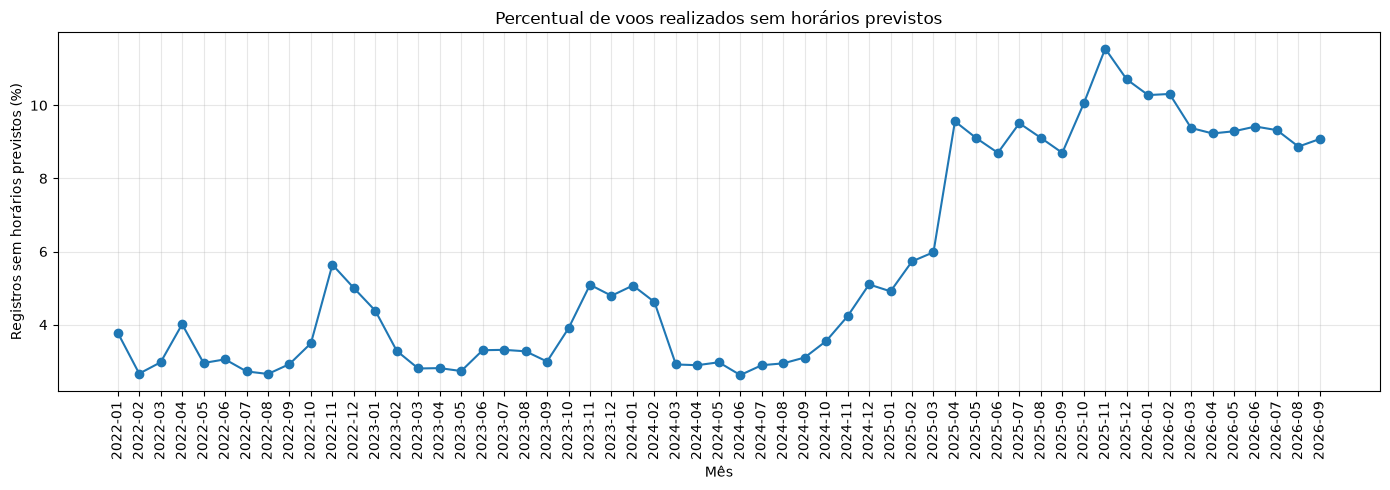

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_df["year"].astype(str) + "-" +
    monthly_df["month"].astype(str).str.zfill(2),
    monthly_df["missing_schedule_pct"],
    marker="o"
)

plt.title("Percentual de voos realizados sem horários previstos")
plt.xlabel("Mês")
plt.ylabel("Registros sem horários previstos (%)")
plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
from pathlib import Path
import pandas as pd

SILVER_DIR = Path("../data/silver")

files = sorted(SILVER_DIR.glob("*/vra_*.parquet"))

results = []

for file in files:
    df = pd.read_parquet(
        file,
        columns=[
            "flight_status",
            "scheduled_departure",
            "scheduled_arrival"
        ]
    )

    realized = df["flight_status"].eq("REALIZADO")

    departure_missing = df["scheduled_departure"].isna()
    arrival_missing = df["scheduled_arrival"].isna()

    results.append({
        "period": file.stem.replace("vra_", ""),
        "realized": realized.sum(),

        "departure_missing": (
            realized & departure_missing
        ).sum(),

        "arrival_missing": (
            realized & arrival_missing
        ).sum(),

        "both_missing": (
            realized & departure_missing & arrival_missing
        ).sum(),

        "either_missing": (
            realized & (departure_missing | arrival_missing)
        ).sum()
    })

missing_analysis = pd.DataFrame(results)

display(missing_analysis)

,period,realized,departure_missing,arrival_missing,both_missing,either_missing
0,2022_01,70137,2651,2651,2651,2651
1,2022_02,56373,1500,1500,1500,1500
2,2022_03,65450,1944,1944,1944,1944
3,2022_04,64086,2571,2571,2571,2571
4,2022_05,69726,2054,2054,2054,2054
5,2022_06,65499,1995,1995,1995,1995
6,2022_07,76387,2081,2081,2081,2081
7,2022_08,73352,1946,1946,1946,1946
8,2022_09,71006,2076,2076,2076,2076
9,2022_10,74541,2602,2602,2602,2602


In [42]:
from pathlib import Path
import pandas as pd

BRONZE_DIR = Path("../data/bronze/anac/vra")

periods = ["20253", "20254"]

for period in periods:

    year = period[:4]
    month = period[4:]

    file_path = (
        BRONZE_DIR /
        year /
        f"VRA_{period}.csv"
    )

    df = pd.read_csv(
        file_path,
        encoding="utf-8-sig",
        sep=";",
        skiprows=1,
        quotechar='"',
        dtype=str,
        keep_default_na=False
    )

    scheduled_columns = [
        "Partida Prevista",
        "Chegada Prevista"
    ]

    missing_departure = (
        df["Partida Prevista"].str.strip().isin(
            ["", "null", "NULL", "None"]
        )
    )

    missing_arrival = (
        df["Chegada Prevista"].str.strip().isin(
            ["", "null", "NULL", "None"]
        )
    )

    realized = df["Situação Voo"].str.strip().eq("REALIZADO")

    print(f"\n--- {year}/{month} ---")
    print("Total de registros:", len(df))
    print("Voos realizados:", realized.sum())

    print(
        "Partida prevista ausente:",
        (realized & missing_departure).sum()
    )

    print(
        "Chegada prevista ausente:",
        (realized & missing_arrival).sum()
    )

    print(
        "Ambas ausentes:",
        (realized & missing_departure & missing_arrival).sum()
    )

    print(
        "Somente partida ausente:",
        (realized & missing_departure & ~missing_arrival).sum()
    )

    print(
        "Somente chegada ausente:",
        (realized & ~missing_departure & missing_arrival).sum()
    )


--- 2025/3 ---
Total de registros: 82048
Voos realizados: 80076
Partida prevista ausente: 1925
Chegada prevista ausente: 1925
Ambas ausentes: 1925
Somente partida ausente: 0
Somente chegada ausente: 0

--- 2025/4 ---
Total de registros: 80692
Voos realizados: 78308
Partida prevista ausente: 2056
Chegada prevista ausente: 2056
Ambas ausentes: 2056
Somente partida ausente: 0
Somente chegada ausente: 0


In [43]:
from pathlib import Path
import pandas as pd

BRONZE_DIR = Path("../data/bronze/anac/vra")

for month in ["20253", "20254"]:

    file_path = BRONZE_DIR / "2025" / f"VRA_{month}.csv"

    df = pd.read_csv(
        file_path,
        encoding="utf-8-sig",
        sep=";",
        skiprows=1,
        quotechar='"',
        dtype=str,
        keep_default_na=False
    )

    realized = df["Situação Voo"].str.strip().eq("REALIZADO")

    print(f"\n========== {month} ==========")

    for column in ["Partida Prevista", "Chegada Prevista"]:

        values = df.loc[realized, column].str.strip()

        parsed = pd.to_datetime(
            values,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce"
        )

        invalid = (
            values.ne("")
            & ~values.isin(["null", "NULL", "None"])
            & parsed.isna()
        )

        print(f"\n{column}")
        print("Valores não vazios e inválidos:", invalid.sum())

        if invalid.any():
            print("\nExemplos:")
            print(values[invalid].value_counts().head(10))


========== 20253 ==========

Partida Prevista
Valores não vazios e inválidos: 2866

Exemplos:
Partida Prevista
2025-03-31 21:05:00.100000000    5
2025-03-31 21:50:00.100000000    4
2025-03-13 01:00:00.100000000    4
2025-03-20 01:00:00.100000000    4
2025-03-30 05:10:00.100000000    4
2025-03-10 01:10:00.100000000    4
2025-03-29 04:00:00.100000000    4
2025-03-06 23:15:00.100000000    4
2025-03-20 23:15:00.100000000    4
2025-03-27 01:00:00.100000000    4
Name: count, dtype: int64

Chegada Prevista
Valores não vazios e inválidos: 2866

Exemplos:
Chegada Prevista
2025-03-26 23:50:00.100000000    4
2025-03-30 08:15:00.100000000    4
2025-03-19 07:15:00.100000000    4
2025-03-05 11:45:00.100000000    4
2025-03-30 19:45:00.100000000    3
2025-03-07 06:00:00.100000000    3
2025-03-14 06:00:00.100000000    3
2025-03-21 06:00:00.100000000    3
2025-03-28 06:00:00.100000000    3
2025-03-10 04:40:00.100000000    3
Name: count, dtype: int64

========== 20254 ==========

Partida Prevista
Valore

In [44]:
for month in ["20253", "20254"]:

    file_path = BRONZE_DIR / "2025" / f"VRA_{month}.csv"

    df = pd.read_csv(
        file_path,
        encoding="utf-8-sig",
        sep=";",
        skiprows=1,
        quotechar='"',
        dtype=str,
        keep_default_na=False
    )

    realized = df["Situação Voo"].str.strip().eq("REALIZADO")

    print(f"\n========== {month} ==========")

    for column in ["Partida Prevista", "Chegada Prevista"]:

        values = df.loc[realized, column].str.strip()

        values = values.replace(
            ["", "null", "NULL", "None"],
            pd.NA
        )

        parsed = pd.to_datetime(
            values,
            format="mixed",
            errors="coerce"
        )

        print(f"\n{column}")
        print("Valores ausentes na origem:", values.isna().sum())
        print("Falhas de conversão:", parsed.isna().sum())
        print("Datas convertidas:", parsed.notna().sum())


========== 20253 ==========

Partida Prevista
Valores ausentes na origem: 1925
Falhas de conversão: 1925
Datas convertidas: 78151

Chegada Prevista
Valores ausentes na origem: 1925
Falhas de conversão: 1925
Datas convertidas: 78151

========== 20254 ==========

Partida Prevista
Valores ausentes na origem: 2056
Falhas de conversão: 2056
Datas convertidas: 76252

Chegada Prevista
Valores ausentes na origem: 2056
Falhas de conversão: 2056
Datas convertidas: 76252
